# Outpatient Claims — Exploratory Data Analysis

Standalone EDA on `data/raw/outpatient_raw.csv`, run **before** any cleaning or joining (see `01_data_loading_joining.ipynb` / `02_cleaning.ipynb`). Mirrors `00a_inpatient_eda.ipynb`, adapted for the outpatient schema — this table has no `AdmissionDt`, `DischargeDt`, or `DiagnosisGroupCode` (those are inherently inpatient concepts), so there's no "length of stay" here, only claim duration.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

from src.data_loader import RAW_DATA_DIR

outpatient = pd.read_csv(RAW_DATA_DIR / 'outpatient_raw.csv')

date_cols = ['ClaimStartDt', 'ClaimEndDt']
for col in date_cols:
    outpatient[col] = pd.to_datetime(outpatient[col], errors='coerce')

outpatient.shape

(517737, 27)

## Shape & Columns

In [2]:
outpatient.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517737 entries, 0 to 517736
Data columns (total 27 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   BeneID                  517737 non-null  object        
 1   ClaimID                 517737 non-null  object        
 2   ClaimStartDt            517737 non-null  datetime64[ns]
 3   ClaimEndDt              517737 non-null  datetime64[ns]
 4   Provider                517737 non-null  object        
 5   InscClaimAmtReimbursed  517737 non-null  int64         
 6   AttendingPhysician      516341 non-null  object        
 7   OperatingPhysician      90617 non-null   object        
 8   OtherPhysician          195046 non-null  object        
 9   ClmDiagnosisCode_1      507284 non-null  object        
 10  ClmDiagnosisCode_2      322357 non-null  object        
 11  ClmDiagnosisCode_3      203257 non-null  object        
 12  ClmDiagnosisCode_4      125596

In [3]:
outpatient.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,DeductibleAmtPaid,ClmAdmitDiagnosisCode
0,BENE11002,CLM624349,2009-10-11,2009-10-11,PRV56011,30,PHY326117,NaN,NaN,78943,V5866,V1272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,56409
1,BENE11003,CLM189947,2009-02-12,2009-02-12,PRV57610,80,PHY362868,NaN,NaN,6115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,79380
2,BENE11003,CLM438021,2009-06-27,2009-06-27,PRV57595,10,PHY328821,NaN,NaN,2723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,BENE11004,CLM121801,2009-01-06,2009-01-06,PRV56011,40,PHY334319,NaN,NaN,71988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
4,BENE11004,CLM150998,2009-01-22,2009-01-22,PRV56011,200,PHY403831,NaN,NaN,82382,30000,72887,4280,7197,V4577,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,71947


## Missing Values

No `AdmissionDt`/`DischargeDt`/`DiagnosisGroupCode` here (inpatient-only columns per `data/raw/raw_data.md`). The remaining sparse columns should be structural for the same reasons as inpatient: `OperatingPhysician`/`OtherPhysician` (missing = no operation / no additional physician), and `ClmDiagnosisCode_5..10` / `ClmProcedureCode_2..6` (most claims don't use that many slots).

In [4]:
missing = pd.DataFrame({
    'n_missing': outpatient.isna().sum(),
    'pct_missing': (outpatient.isna().mean() * 100).round(2),
    'dtype': outpatient.dtypes,
})
missing.sort_values('pct_missing', ascending=False)

,n_missing,pct_missing,dtype
ClmProcedureCode_6,517737,100.00,float64
ClmProcedureCode_5,517737,100.00,float64
ClmProcedureCode_4,517735,100.00,float64
ClmProcedureCode_3,517733,100.00,float64
ClmProcedureCode_2,517701,99.99,float64
ClmProcedureCode_1,517575,99.97,float64
ClmDiagnosisCode_10,516654,99.79,object
ClmDiagnosisCode_9,502899,97.13,object
ClmDiagnosisCode_8,494825,95.57,object
ClmDiagnosisCode_7,484776,93.63,object


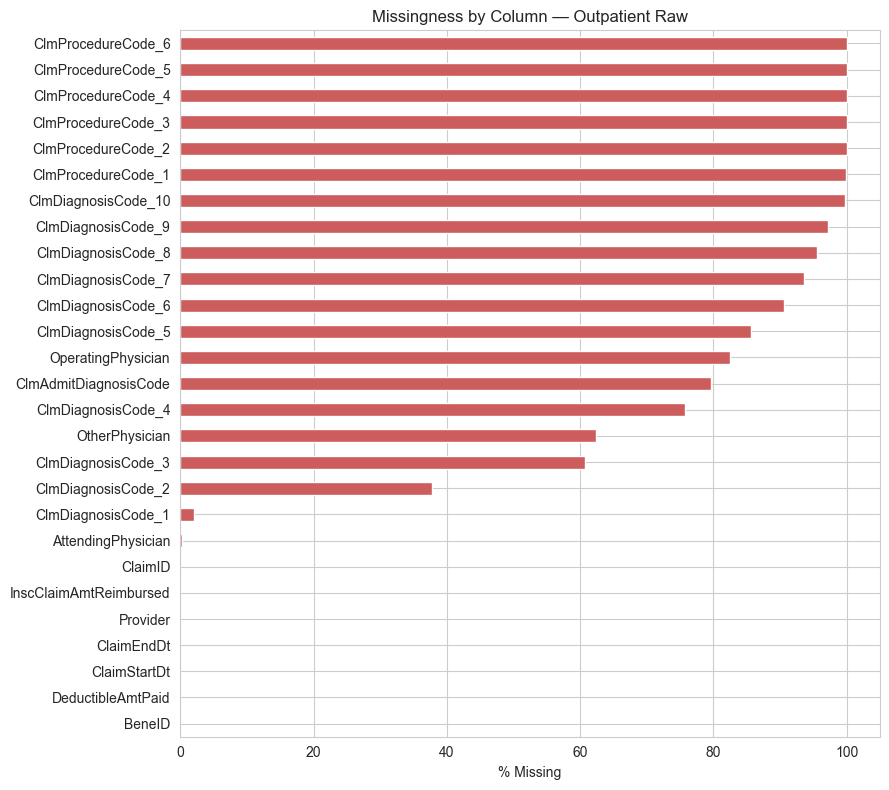

In [5]:
missing_pct = missing['pct_missing'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 8))
missing_pct.plot(kind='barh', ax=ax, color='indianred')
ax.invert_yaxis()
ax.set_xlabel('% Missing')
ax.set_title('Missingness by Column — Outpatient Raw')
plt.tight_layout()
plt.show()

## Row-Level Integrity Checks

In [6]:
print('Total rows:', len(outpatient))
print('Unique ClaimID:', outpatient['ClaimID'].nunique())
print('Duplicate ClaimID rows:', outpatient['ClaimID'].duplicated().sum())
print('Fully duplicated rows:', outpatient.duplicated().sum())
print('Unique BeneID (patients):', outpatient['BeneID'].nunique())
print('Unique Provider:', outpatient['Provider'].nunique())

Total rows: 517737
Unique ClaimID: 517737
Duplicate ClaimID rows: 0


Fully duplicated rows: 0
Unique BeneID (patients): 133980
Unique Provider: 5012


## Claim Duration

In [7]:
print('ClaimStartDt range:', outpatient['ClaimStartDt'].min(), '->', outpatient['ClaimStartDt'].max())

outpatient['ClaimDuration'] = (outpatient['ClaimEndDt'] - outpatient['ClaimStartDt']).dt.days
outpatient['ClaimDuration'].describe()

ClaimStartDt range: 2008-12-12 00:00:00 -> 2009-12-31 00:00:00


count    517737.000000
mean          1.420532
std           4.707387
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          23.000000
Name: ClaimDuration, dtype: float64

In [8]:
print('Negative ClaimDuration rows:', (outpatient['ClaimDuration'] < 0).sum())
print('ClaimDuration == 0 rows (same-day claims):', (outpatient['ClaimDuration'] == 0).sum(),
      f"({(outpatient['ClaimDuration'] == 0).mean() * 100:.1f}%)")

Negative ClaimDuration rows: 0
ClaimDuration == 0 rows (same-day claims): 453348 (87.6%)


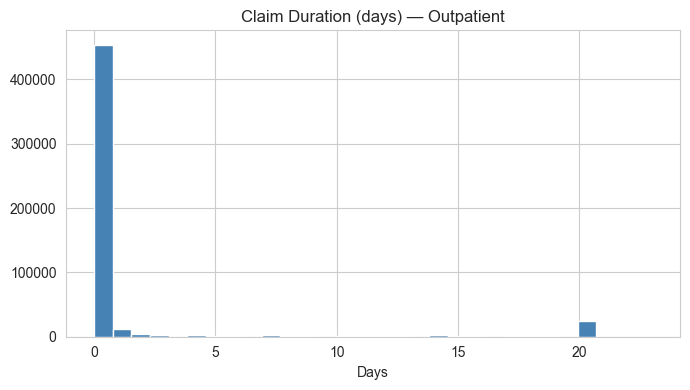

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(outpatient['ClaimDuration'].dropna(), bins=30, color='steelblue')
ax.set_title('Claim Duration (days) — Outpatient')
ax.set_xlabel('Days')
plt.tight_layout()
plt.show()

## Reimbursement & Deductible Amounts

In [10]:
outpatient[['InscClaimAmtReimbursed', 'DeductibleAmtPaid']].describe()

,InscClaimAmtReimbursed,DeductibleAmtPaid
count,517737.000000,517737.000000
mean,286.334799,2.779233
std,694.034343,15.785839
min,0.000000,0.000000
25%,40.000000,0.000000
50%,80.000000,0.000000
75%,200.000000,0.000000
max,102500.000000,897.000000


Zero-reimbursement claims: 19568 (3.8%)
Zero-deductible claims:     496701 (95.9%)


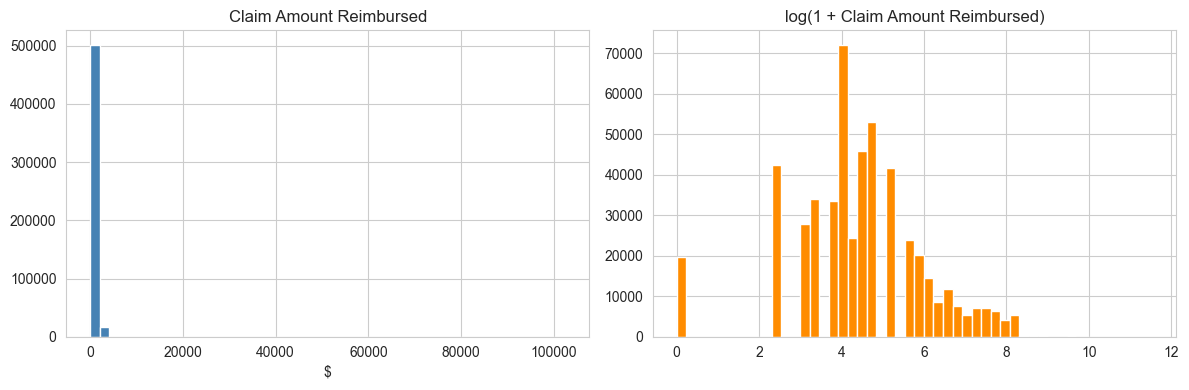

In [11]:
print('Zero-reimbursement claims:', (outpatient['InscClaimAmtReimbursed'] == 0).sum(),
      f"({(outpatient['InscClaimAmtReimbursed'] == 0).mean() * 100:.1f}%)")
print('Zero-deductible claims:    ', (outpatient['DeductibleAmtPaid'] == 0).sum(),
      f"({(outpatient['DeductibleAmtPaid'] == 0).mean() * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(outpatient['InscClaimAmtReimbursed'], bins=50, color='steelblue')
axes[0].set_title('Claim Amount Reimbursed')
axes[0].set_xlabel('$')

axes[1].hist(np.log1p(outpatient['InscClaimAmtReimbursed']), bins=50, color='darkorange')
axes[1].set_title('log(1 + Claim Amount Reimbursed)')
plt.tight_layout()
plt.show()

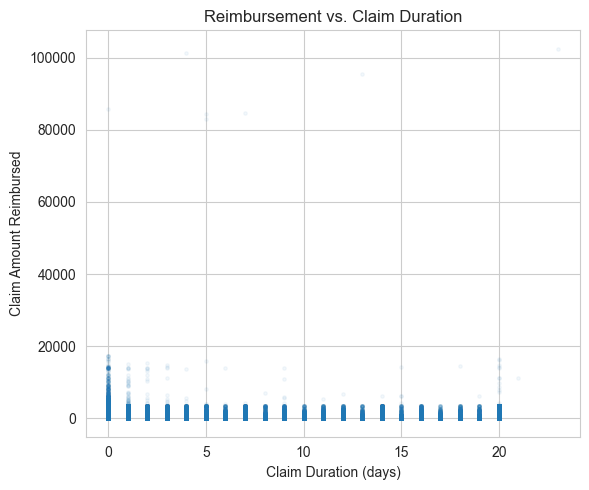

Correlation (ClaimDuration, InscClaimAmtReimbursed): 0.223


In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(outpatient['ClaimDuration'], outpatient['InscClaimAmtReimbursed'], alpha=0.05, s=6)
ax.set_xlabel('Claim Duration (days)')
ax.set_ylabel('Claim Amount Reimbursed')
ax.set_title('Reimbursement vs. Claim Duration')
plt.tight_layout()
plt.show()

print('Correlation (ClaimDuration, InscClaimAmtReimbursed):',
      outpatient[['ClaimDuration', 'InscClaimAmtReimbursed']].corr().iloc[0, 1].round(3))

## Diagnosis Codes

In [13]:
print('Top 10 admission diagnosis codes (ClmAdmitDiagnosisCode):')
outpatient['ClmAdmitDiagnosisCode'].value_counts().head(10)

Top 10 admission diagnosis codes (ClmAdmitDiagnosisCode):


ClmAdmitDiagnosisCode
V7612    4074
42731    3001
4019     2627
25000    2346
V5883    1871
7295     1616
78900    1550
V5861    1536
2724     1506
7242     1432
Name: count, dtype: int64

In [14]:
print('Top 10 primary diagnosis codes (ClmDiagnosisCode_1):')
outpatient['ClmDiagnosisCode_1'].value_counts().head(10)

Top 10 primary diagnosis codes (ClmDiagnosisCode_1):


ClmDiagnosisCode_1
4019     13803
4011     12512
2724      3603
2720      3209
2722      3028
2721      2998
2723      2995
78651     2251
78659     2181
78650     2179
Name: count, dtype: int64

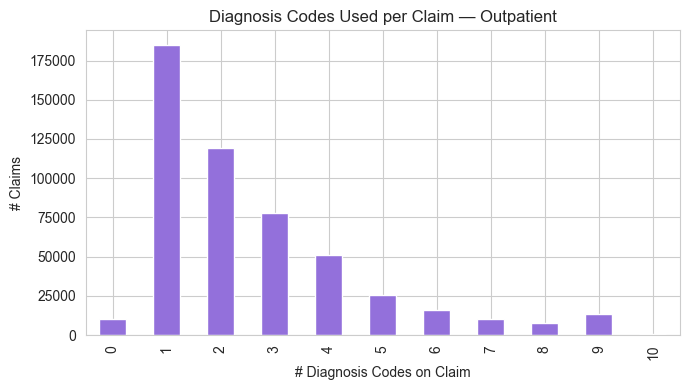

In [15]:
diag_cols = [f'ClmDiagnosisCode_{i}' for i in range(1, 11)]
outpatient['NumDiagnosisCodes'] = outpatient[diag_cols].notna().sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
outpatient['NumDiagnosisCodes'].value_counts().sort_index().plot(kind='bar', ax=ax, color='mediumpurple')
ax.set_xlabel('# Diagnosis Codes on Claim')
ax.set_ylabel('# Claims')
ax.set_title('Diagnosis Codes Used per Claim — Outpatient')
plt.tight_layout()
plt.show()

## Procedure Codes

In [16]:
print('Top 10 primary procedure codes (ClmProcedureCode_1):')
print(outpatient['ClmProcedureCode_1'].value_counts().head(10))

proc_cols = [f'ClmProcedureCode_{i}' for i in range(1, 7)]
outpatient['NumProcedureCodes'] = outpatient[proc_cols].notna().sum(axis=1)
outpatient['NumProcedureCodes'].value_counts().sort_index()

Top 10 primary procedure codes (ClmProcedureCode_1):
ClmProcedureCode_1
9904.0    15
3722.0     8
4516.0     8
66.0       7
5123.0     7
9672.0     5
3893.0     5
9952.0     5
9955.0     4
8622.0     4
Name: count, dtype: int64


NumProcedureCodes
0    517575
1       126
2        32
3         2
4         2
Name: count, dtype: int64

## Physician Involvement

In [17]:
for col in ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']:
    print(f"{col}: {outpatient[col].notna().mean() * 100:.1f}% present, {outpatient[col].nunique()} unique")

phys_cols = ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']
outpatient['NumPhysiciansInvolved'] = outpatient[phys_cols].notna().sum(axis=1)
outpatient['NumPhysiciansInvolved'].value_counts().sort_index()

AttendingPhysician: 99.7% present, 74109 unique

OperatingPhysician: 17.5% present, 28532 unique
OtherPhysician: 37.7% present, 44388 unique


NumPhysiciansInvolved
0      1377
1    271360
2    204356
3     40644
Name: count, dtype: int64

## Claim Volume per Provider & Beneficiary

Providers with >=1 outpatient claim: 5012 | median claims/provider: 31.0
Beneficiaries with >=1 outpatient claim: 133980 | median claims/beneficiary: 3.0


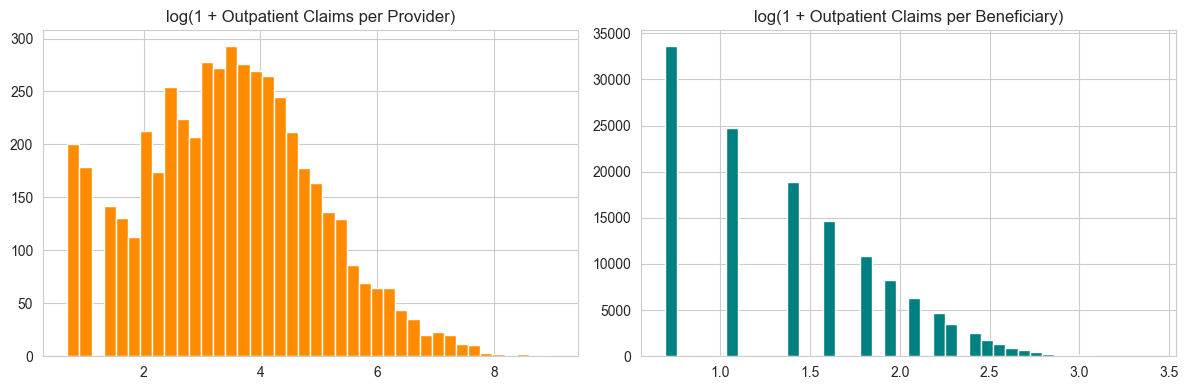

In [18]:
claims_per_provider = outpatient.groupby('Provider')['ClaimID'].count().sort_values(ascending=False)
claims_per_bene = outpatient.groupby('BeneID')['ClaimID'].count().sort_values(ascending=False)

print('Providers with >=1 outpatient claim:', outpatient['Provider'].nunique(),
      '| median claims/provider:', claims_per_provider.median())
print('Beneficiaries with >=1 outpatient claim:', outpatient['BeneID'].nunique(),
      '| median claims/beneficiary:', claims_per_bene.median())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(claims_per_provider), bins=40, color='darkorange')
axes[0].set_title('log(1 + Outpatient Claims per Provider)')
axes[1].hist(np.log1p(claims_per_bene), bins=40, color='teal')
axes[1].set_title('log(1 + Outpatient Claims per Beneficiary)')
plt.tight_layout()
plt.show()

In [19]:
print('Top 10 beneficiaries by outpatient claim count (repeat-visit signal):')
claims_per_bene.head(10)

Top 10 beneficiaries by outpatient claim count (repeat-visit signal):


BeneID
BENE42721     29
BENE118316    29
BENE63544     27
BENE59303     27
BENE143400    27
BENE63504     27
BENE36330     26
BENE44241     26
BENE87248     25
BENE40202     25
Name: ClaimID, dtype: int64

## Fraud Label Context

The target label lives at the provider level (`provider_labels.csv`), not on the claims table itself. Joining it in here — purely for EDA, not as part of the cleaning pipeline — shows whether outpatient-claim-level features already separate fraud groups before any feature engineering.

In [20]:
labels = pd.read_csv(RAW_DATA_DIR / 'provider_labels.csv')
outpatient_labeled = outpatient.merge(labels, on='Provider', how='left')
outpatient_labeled['PotentialFraud'] = outpatient_labeled['PotentialFraud'].map({'Yes': 1, 'No': 0})

outpatient_labeled.groupby('PotentialFraud')[
    ['InscClaimAmtReimbursed', 'DeductibleAmtPaid', 'ClaimDuration', 'NumPhysiciansInvolved']
].mean().round(2)

,InscClaimAmtReimbursed,DeductibleAmtPaid,ClaimDuration,NumPhysiciansInvolved
PotentialFraud,,,,
0,285.84,2.78,1.41,1.55
1,287.19,2.77,1.43,1.55


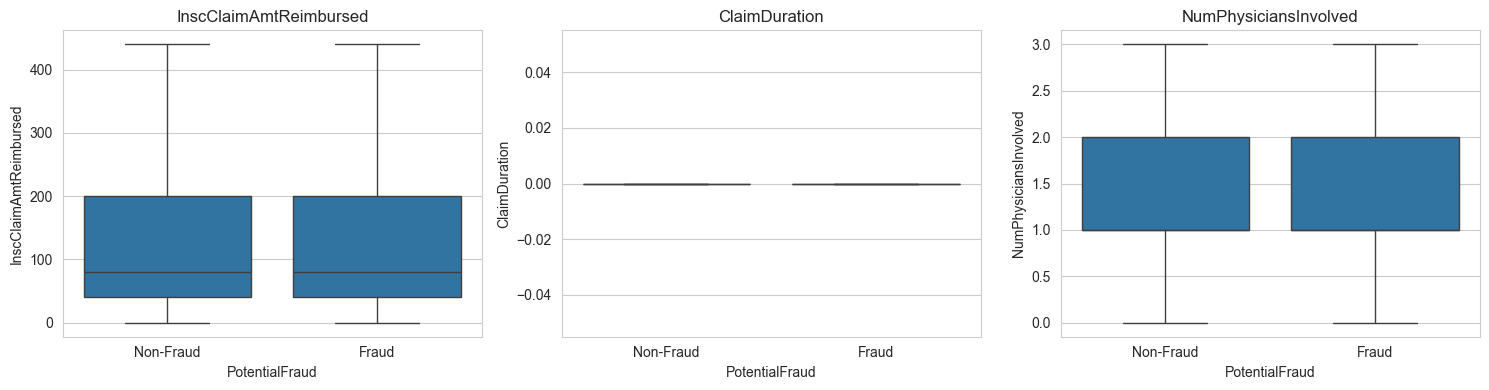

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['InscClaimAmtReimbursed', 'ClaimDuration', 'NumPhysiciansInvolved']):
    sns.boxplot(data=outpatient_labeled, x='PotentialFraud', y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Non-Fraud', 'Fraud'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

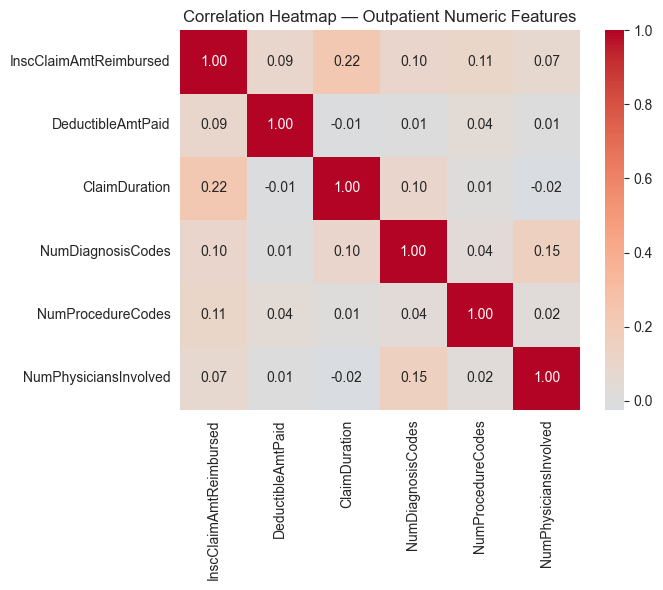

In [22]:
numeric_cols = ['InscClaimAmtReimbursed', 'DeductibleAmtPaid', 'ClaimDuration',
                'NumDiagnosisCodes', 'NumProcedureCodes', 'NumPhysiciansInvolved']
corr = outpatient_labeled[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap — Outpatient Numeric Features')
plt.tight_layout()
plt.show()

## Comparison to Inpatient

A few quick cross-checks against `00a_inpatient_eda.ipynb`'s findings, since both tables feed the same downstream `combine_claims()` step.

In [23]:
inpatient = pd.read_csv(RAW_DATA_DIR / 'inpatient_raw.csv')

print(f"Outpatient claims: {len(outpatient):,} | Inpatient claims: {len(inpatient):,}")
print(f"Outpatient share of combined claims: {len(outpatient) / (len(outpatient) + len(inpatient)) * 100:.1f}%")
print()
print('Mean InscClaimAmtReimbursed — Outpatient:', round(outpatient['InscClaimAmtReimbursed'].mean(), 2),
      '| Inpatient:', round(inpatient['InscClaimAmtReimbursed'].mean(), 2))
print('Median InscClaimAmtReimbursed — Outpatient:', outpatient['InscClaimAmtReimbursed'].median(),
      '| Inpatient:', inpatient['InscClaimAmtReimbursed'].median())

Outpatient claims: 517,737 | Inpatient claims: 40,474
Outpatient share of combined claims: 92.7%

Mean InscClaimAmtReimbursed — Outpatient: 286.33 | Inpatient: 10087.88
Median InscClaimAmtReimbursed — Outpatient: 80.0 | Inpatient: 7000.0


## Summary of Findings

**Shape & scale**
- 517,737 outpatient claims, 27 raw columns (no `AdmissionDt`/`DischargeDt`/`DiagnosisGroupCode` — those are inpatient-only). That's **~12.8x more rows than inpatient** (40,474) — outpatient makes up 92.7% of combined claim volume.
- 133,980 unique beneficiaries and 5,012 unique providers (vs. 31,289 / 2,092 for inpatient) — outpatient reaches a much broader slice of both patients and providers.
- Median **31 claims per provider** and **3 claims per beneficiary** (vs. 8 and 1 for inpatient) — outpatient care is dominated by repeat visits, not one-off events.
- `ClaimID` is unique and there are no fully duplicated rows — clean at the row level, same as inpatient.

**Missingness — the pattern is very different from inpatient**
- Procedure codes are essentially unused: `ClmProcedureCode_1` is **99.97% missing** (only 162 of 517,737 claims have any procedure code at all), vs. 42.8% missing in inpatient. Outpatient visits almost never involve a recorded procedure.
- `ClmAdmitDiagnosisCode` is 79.6% missing here (vs. 0% missing in inpatient) — it's an admission-related field, so it's only populated for a minority of outpatient visits.
- `ClmDiagnosisCode_1` (primary diagnosis) itself is missing on 2.0% of claims (10,453 rows) — inpatient claims always have this filled; outpatient claims sometimes have **no diagnosis code recorded at all**.
- `OperatingPhysician` is 82.5% missing (vs. 41.1% for inpatient) — consistent with far fewer procedures.
- **`DeductibleAmtPaid` behaves oppositely to inpatient**: 0% missing here, and it is *not* constant — mean $2.78, std $15.79, up to $897. In inpatient it was ~constant at $1,068 wherever present (near-zero information); in outpatient it's a genuinely variable numeric feature.

**Claim duration (no length-of-stay concept here)**
- 87.6% of outpatient claims are same-day (`ClaimDuration` = 0); mean 1.42 days, max 23 days. Outpatient visits are overwhelmingly single-day, unlike inpatient's ~5.7-day average stay.

**Reimbursement**
- Far smaller dollar amounts than inpatient: mean **$286** vs. $10,088, median **$80** vs. $7,000 — roughly a **35x scale difference**. Pooling `InscClaimAmtReimbursed` across both claim types without keeping `ClaimType` as a feature would badly conflate two very different distributions — reinforces why `combine_claims()` tags rows with `ClaimType`.
- 3.8% zero-reimbursement claims (vs. 2.7% inpatient).
- 95.9% of claims have **$0 deductible paid** (vs. inpatient's ~constant $1,068) — deductible behaves fundamentally differently by claim type.
- Correlation between duration and reimbursement is weak here too (0.22), similar in spirit to inpatient's 0.32.

**Diagnosis & procedure codes**
- Top admission diagnosis is `V7612` (routine screening, n=4,074); top primary diagnosis is `4019` (essential hypertension, n=13,803), followed by `4011` (hypertension, n=12,512) — dominated by routine/chronic-condition codes, a sharp contrast to inpatient's acute-care codes (pneumonia `486` was #1 there).
- With procedure codes present on only 0.03% of claims, `ClmProcedureCode_*` is effectively an **inpatient-only signal** — for outpatient, a simple `HasProcedure` flag captures almost all the available information; the raw code columns aren't usable as-is.

**Physician involvement**
- `AttendingPhysician` present on 99.7% of claims (same as inpatient), but `OperatingPhysician` only 17.5% (vs. 58.9% inpatient) and `OtherPhysician` 37.7% (vs. 11.6% inpatient — actually *higher* here). Most claims (271,360) involve exactly 1 physician; 1,377 claims list none.

**Fraud label context (claim-level, provider label joined in for reference only)**
- Same pattern as inpatient: claim-level means for Fraud vs. Non-Fraud are nearly flat (reimbursed $287.19 vs. $285.84, duration 1.43 vs. 1.41 days, physicians 1.55 vs. 1.55). Confirms again that fraud signal doesn't show up in raw per-claim averages — it needs provider-level aggregation.

**Implications for cleaning / feature engineering**
1. Keep `ClaimType` as a first-class feature (or model outpatient/inpatient separately for some features) — reimbursement, deductible, and duration are *structurally* different distributions between the two tables, not just rescaled versions of each other.
2. `DeductibleAmtPaid` is informative for outpatient but near-constant for inpatient — don't treat it identically across claim types; consider a claim-type-aware transform or provider-level aggregate instead of the raw value.
3. Collapse `ClmProcedureCode_*` to a `HasProcedure` binary flag for outpatient rather than trying to use the individual codes — there's essentially no data there.
4. Handle the outpatient-specific missingness on `ClmDiagnosisCode_1` / `ClmAdmitDiagnosisCode` explicitly (e.g. an `IsMissing` flag or "no diagnosis recorded" category) — this doesn't happen in inpatient.
5. As with inpatient, any fraud comparison or model feature should be built on **provider-level aggregates**, not raw claim rows — claim-level fraud/non-fraud differences are essentially flat in both tables.